In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto sólo se conocen sus rutas entre el nodo inicial y el final y las duraciones de sus actividades (en días).

In [4]:
pregunta_1 = "1. Construya la matriz de caminos del proyecto.  "
pregunta_2 = "2. Calcule con ella la duración del proyecto e identifique la ruta crítica.  "
pregunta_3 = "3. Reconstruya el cuadro de prelaciones inmediatas y dibuje los grafos PERT y Roy. Compruebe que sus rutas son las del enunciado.  "
pregunta_4 = "4. Calcule la sensibilidad de la duración del proyecto a cada actividad: ¿en cuánto aumenta la duración si una actividad dura un día más?  "
pregunta_5 = "5. Calcule la descomposición en valores singulares de la matriz de caminos y ordene rutas y actividades según el primer vector singular. Compare con la ruta crítica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya la matriz de caminos del proyecto.  

2. Calcule con ella la duración del proyecto e identifique la ruta crítica.  

3. Reconstruya el cuadro de prelaciones inmediatas y dibuje los grafos PERT y Roy. Compruebe que sus rutas son las del enunciado.  

4. Calcule la sensibilidad de la duración del proyecto a cada actividad: ¿en cuánto aumenta la duración si una actividad dura un día más?  

5. Calcule la descomposición en valores singulares de la matriz de caminos y ordene rutas y actividades según el primer vector singular. Compare con la ruta crítica.  

In [5]:
#| tbl-cap: "Rutas del proyecto"
#| label: tbl-datosRutas
rutas_enunciado = {
    'Route_1': ['A', 'C', 'D', 'F', 'H', 'I'],
    'Route_2': ['A', 'C', 'D', 'G', 'I'],
    'Route_3': ['A', 'C', 'E', 'F', 'H', 'I'],
    'Route_4': ['A', 'C', 'E', 'G', 'I'],
    'Route_5': ['B', 'C', 'D', 'F', 'H', 'I'],
    'Route_6': ['B', 'C', 'D', 'G', 'I'],
    'Route_7': ['B', 'C', 'E', 'F', 'H', 'I'],
    'Route_8': ['B', 'C', 'E', 'G', 'I'],
}
pd.Series({r: ' - '.join(a) for r, a in rutas_enunciado.items()}).to_frame('actividades')

,actividades
Route_1,A - C - D - F - H - I
Route_2,A - C - D - G - I
Route_3,A - C - E - F - H - I
Route_4,A - C - E - G - I
Route_5,B - C - D - F - H - I
Route_6,B - C - D - G - I
Route_7,B - C - E - F - H - I
Route_8,B - C - E - G - I


In [6]:
#| tbl-cap: "Duración de las actividades"
#| label: tbl-datosDuraciones
datos_enunciado = pd.DataFrame([
#  activity, duration
    ('A'     , 6       ),
    ('B'     , 1       ),
    ('C'     , 8       ),
    ('D'     , 1       ),
    ('E'     , 5       ),
    ('F'     , 1       ),
    ('G'     , 3       ),
    ('H'     , 7       ),
    ('I'     , 7       ),
], columns=['activity', 'duration']).set_index('activity')
datos_enunciado

,duration
activity,
A,6
B,1
C,8
D,1
E,5
F,1
G,3
H,7
I,7


El proyecto corresponde a la instalación de una planta fotovoltaica sobre cubierta; las actividades son las siguientes (las duraciones del cuadro están en días).

In [7]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de sombras y producción',
    'B': 'Cálculo estructural de la cubierta',
    'C': 'Tramitación de permisos',
    'D': 'Acopio de módulos e inversores',
    'E': 'Montaje de la estructura soporte',
    'F': 'Colocación de módulos',
    'G': 'Cableado de corriente continua',
    'H': 'Instalación de inversores',
    'I': 'Cuadro de protecciones y contador',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de sombras y producción
B,Cálculo estructural de la cubierta
C,Tramitación de permisos
D,Acopio de módulos e inversores
E,Montaje de la estructura soporte
F,Colocación de módulos
G,Cableado de corriente continua
H,Instalación de inversores
I,Cuadro de protecciones y contador


# Resolución

In [8]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Construya la matriz de caminos del proyecto.  

La matriz de caminos tiene un 1 en la fila de una ruta y la columna de una actividad cuando la actividad pertenece a la ruta.

In [10]:
actividades = sorted(set(a for acts in rutas_enunciado.values() for a in acts))
path_matrix = pd.DataFrame(0, index=list(rutas_enunciado), columns=actividades)
for ruta, acts in rutas_enunciado.items():
    path_matrix.loc[ruta, acts] = 1
path_matrix

,A,B,C,D,E,F,G,H,I
Route_1,1,0,1,1,0,1,0,1,1
Route_2,1,0,1,1,0,0,1,0,1
Route_3,1,0,1,0,1,1,0,1,1
Route_4,1,0,1,0,1,0,1,0,1
Route_5,0,1,1,1,0,1,0,1,1
Route_6,0,1,1,1,0,0,1,0,1
Route_7,0,1,1,0,1,1,0,1,1
Route_8,0,1,1,0,1,0,1,0,1


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Calcule con ella la duración del proyecto e identifique la ruta crítica.  

In [12]:
duraciones = datos_enunciado['duration'].reindex(actividades)
duraciones_rutas = path_matrix @ duraciones
Math(bmatrix(path_matrix) + r' \times ' + bmatrix(duraciones) + ' = ' + bmatrix(duraciones_rutas))

<IPython.core.display.Math object>

In [13]:
#| tbl-cap: "Duración de cada ruta, sumando sus actividades"
#| label: tbl-rutasPaso-a
detalle_rutas(path_matrix, duraciones)

,actividades,duración = suma,duración
Route_1,A - C - D - F - H - I,A(6) + C(8) + D(1) + F(1) + H(7) + I(7) = 30,30.0
Route_2,A - C - D - G - I,A(6) + C(8) + D(1) + G(3) + I(7) = 25,25.0
Route_3,A - C - E - F - H - I,A(6) + C(8) + E(5) + F(1) + H(7) + I(7) = 34,34.0
Route_4,A - C - E - G - I,A(6) + C(8) + E(5) + G(3) + I(7) = 29,29.0
Route_5,B - C - D - F - H - I,B(1) + C(8) + D(1) + F(1) + H(7) + I(7) = 25,25.0
Route_6,B - C - D - G - I,B(1) + C(8) + D(1) + G(3) + I(7) = 20,20.0
Route_7,B - C - E - F - H - I,B(1) + C(8) + E(5) + F(1) + H(7) + I(7) = 29,29.0
Route_8,B - C - E - G - I,B(1) + C(8) + E(5) + G(3) + I(7) = 24,24.0


In [14]:
duracion_proyecto = int(duraciones_rutas.max())
ruta_critica = duraciones_rutas.idxmax()
Markdown(f'La duración del proyecto es {duracion_proyecto} días, la de la ruta más larga, {ruta_critica}: '
         f'{" - ".join(rutas_enunciado[ruta_critica])}.')

La duración del proyecto es 34 días, la de la ruta más larga, Route_3: A - C - E - F - H - I.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Reconstruya el cuadro de prelaciones inmediatas y dibuje los grafos PERT y Roy. Compruebe que sus rutas son las del enunciado.  

Las predecesoras inmediatas de una actividad son las que la preceden inmediatamente en alguna ruta; las rutas son todas las secuencias posibles, así que el conjunto de parejas consecutivas de todas las rutas es exactamente el cuadro de prelaciones inmediatas. Las actividades que abren alguna ruta son iniciales.

In [16]:
prelaciones_dict = {a: set() for a in actividades}
for acts in rutas_enunciado.values():
    for anterior, posterior in zip(acts[:-1], acts[1:]):
        prelaciones_dict[posterior].add(anterior)
datos_proyecto = pd.DataFrame({'predecessor': pd.Series({a: ','.join(sorted(p)) or '---' for a, p in prelaciones_dict.items()}),
                               'duration': duraciones})
datos_proyecto.index.name = 'activity'
datos_proyecto

,predecessor,duration
activity,,
A,---,6
B,---,1
C,"A,B",8
D,C,1
E,C,5
F,"D,E",1
G,"D,E",3
H,F,7
I,"G,H",7


In [17]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

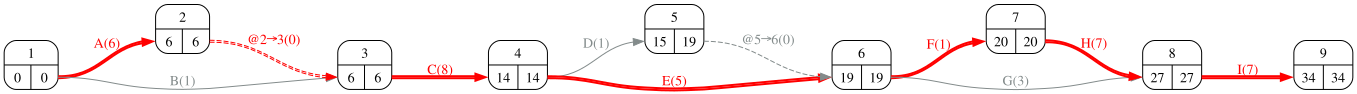

In [18]:
#| fig-cap: "Grafo PERT reconstruido, con tiempos y ruta crítica"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

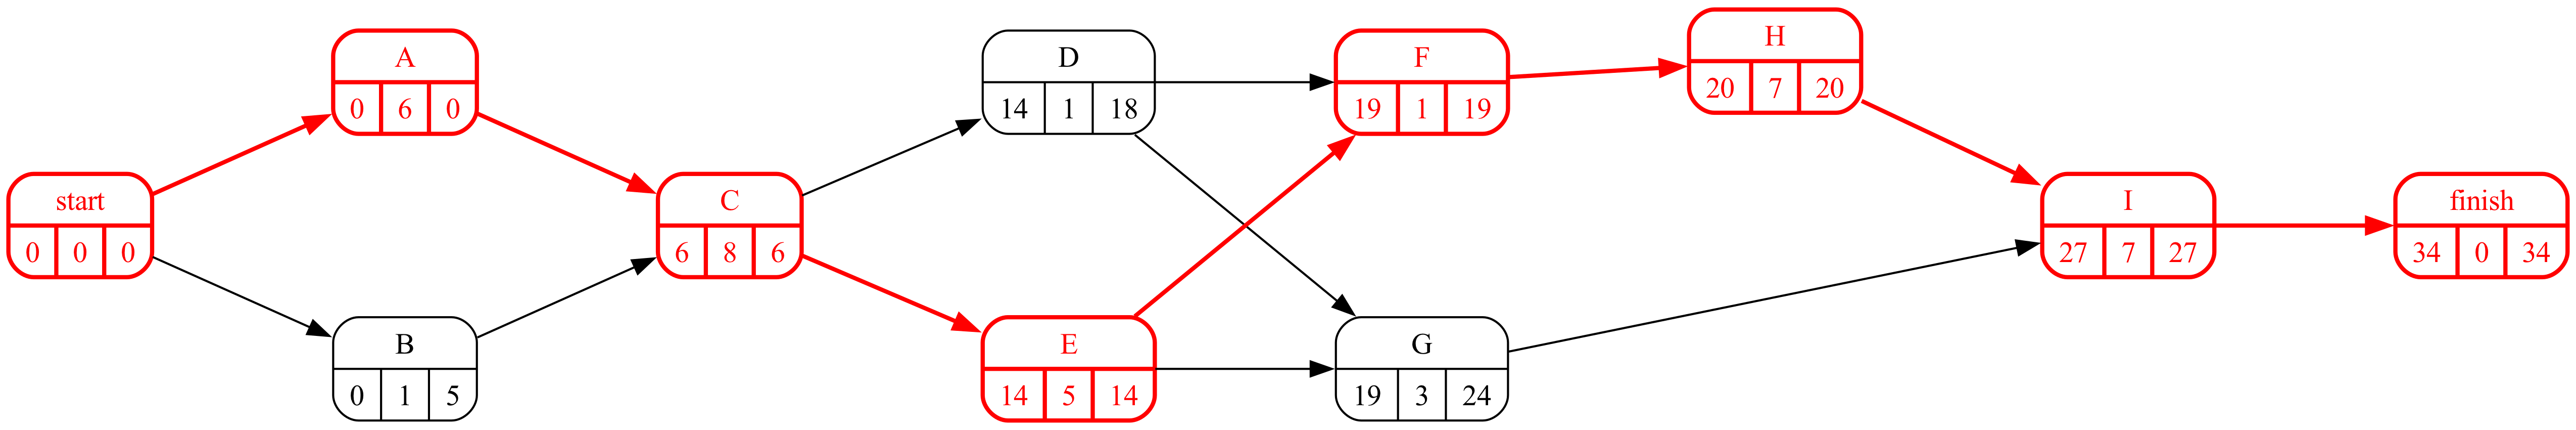

In [19]:
#| fig-cap: "Grafo Roy reconstruido"
#| label: fig-roy
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [20]:
rutas_grafo = {' - '.join(a) for a in proyecto.paths(dummies=False).values()}
rutas_dadas = {' - '.join(a) for a in rutas_enunciado.values()}
print('Las rutas del grafo coinciden con las del enunciado:', rutas_grafo == rutas_dadas)

Las rutas del grafo coinciden con las del enunciado: True


## Apartado 4

In [21]:
display(Markdown(pregunta_4))

4. Calcule la sensibilidad de la duración del proyecto a cada actividad: ¿en cuánto aumenta la duración si una actividad dura un día más?  

La duración del proyecto es $\tau = \max_r (P\,d)_r$. Si una actividad crítica dura un día más, la ruta crítica se alarga un día y con ella el proyecto: su sensibilidad es 1. Si una actividad no crítica dura un día más, la ruta más larga no cambia mientras no se agote la holgura: sensibilidad 0. Al acortar una actividad crítica el proyecto sólo se acorta hasta que otra ruta pasa a ser la más larga.

In [22]:
sensibilidad = proyecto.tau_sensitivity(duraciones.to_dict())
holgura = duracion_proyecto - duraciones_rutas
segunda = holgura[holgura > 0].min() if (holgura > 0).any() else None
pd.DataFrame({'sensibilidad (+1 día)': sensibilidad.reindex(duraciones.index)}).T

activity,A,B,C,D,E,F,G,H,I
sensibilidad (+1 día),1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0


In [23]:
comprobacion = {}
for act in duraciones.index:
    mas = duraciones.copy(); mas[act] += 1
    menos = duraciones.copy(); menos[act] -= 1
    comprobacion[act] = {'+1 día': int((path_matrix @ mas).max()) - duracion_proyecto,
                         '-1 día': int((path_matrix @ menos).max()) - duracion_proyecto}
pd.DataFrame(comprobacion)

,A,B,C,D,E,F,G,H,I
+1 día,1,0,1,0,1,1,0,1,1
-1 día,-1,0,-1,0,-1,-1,0,-1,-1


In [24]:
Markdown(f'Al acortar una actividad crítica el proyecto se reduce un día sólo si ninguna otra ruta alcanza la duración máxima; '
         f'la segunda ruta más larga está a {segunda} día(s) de la crítica, así que esa es la reducción máxima que puede conseguirse '
         'acortando una única actividad crítica que no pertenezca también a esa segunda ruta.')

Al acortar una actividad crítica el proyecto se reduce un día sólo si ninguna otra ruta alcanza la duración máxima; la segunda ruta más larga está a 4 día(s) de la crítica, así que esa es la reducción máxima que puede conseguirse acortando una única actividad crítica que no pertenezca también a esa segunda ruta.

## Apartado 5

In [25]:
display(Markdown(pregunta_5))

5. Calcule la descomposición en valores singulares de la matriz de caminos y ordene rutas y actividades según el primer vector singular. Compare con la ruta crítica.  

La descomposición en valores singulares $P = U\,S\,V^T$ ordena la información de la matriz de caminos por importancia. El primer vector singular por la izquierda, $u_1$, pondera las rutas, y el primero por la derecha, $v_1$, las actividades: las actividades que aparecen en muchas rutas y las rutas que contienen muchas actividades compartidas reciben más peso. Es una ordenación estructural, que no usa las duraciones, y por eso no tiene por qué coincidir con la ruta crítica.

In [26]:
U, S, Vt = np.linalg.svd(path_matrix.values.astype(float))
u1 = np.abs(U[:, 0]); v1 = np.abs(Vt[0, :])
importancia_rutas = pd.Series(u1 / u1.sum(), index=path_matrix.index)
importancia_actividades = pd.Series(v1 / v1.sum(), index=path_matrix.columns)
Math(r'S = ' + bmatrix(S.round(2), dec=2))

<IPython.core.display.Math object>

In [27]:
#| tbl-cap: "Rutas y actividades ordenadas por su peso en el primer vector singular"
#| label: tbl-svd
ordena_rutas(path_matrix.copy(), importancia_actividades.values, importancia_rutas.values)

,I,C,H,F,A,D,E,B,G,Importancia
Route_3,0.180460,0.180460,0.097698,0.097698,0.090230,0.000000,0.090230,0.000000,0.000000,0.135345
Route_1,0.180460,0.180460,0.097698,0.097698,0.090230,0.090230,0.000000,0.000000,0.000000,0.135345
Route_7,0.180460,0.180460,0.097698,0.097698,0.000000,0.000000,0.090230,0.090230,0.000000,0.135345
Route_5,0.180460,0.180460,0.097698,0.097698,0.000000,0.090230,0.000000,0.090230,0.000000,0.135345
Route_2,0.180460,0.180460,0.000000,0.000000,0.090230,0.090230,0.000000,0.000000,0.082763,0.114655
Route_4,0.180460,0.180460,0.000000,0.000000,0.090230,0.000000,0.090230,0.000000,0.082763,0.114655
Route_6,0.180460,0.180460,0.000000,0.000000,0.000000,0.090230,0.000000,0.090230,0.082763,0.114655
Route_8,0.180460,0.180460,0.000000,0.000000,0.000000,0.000000,0.090230,0.090230,0.082763,0.114655


In [28]:
Markdown(f'La ruta dominante según la SVD es {importancia_rutas.idxmax()} y la ruta crítica es {ruta_critica}. '
         f'La actividad de mayor peso es {importancia_actividades.idxmax()}, que aparece en '
         f'{int(path_matrix[importancia_actividades.idxmax()].sum())} de las {len(path_matrix)} rutas.')

La ruta dominante según la SVD es Route_3 y la ruta crítica es Route_3. La actividad de mayor peso es C, que aparece en 8 de las 8 rutas.